# 032 — CatBoost + ensemble 025

Mistura o ensemble original 025 (XGBoost + MLP, 75/25, dropout 0,1, 85 épocas) com CatBoost original 029 (sem pesos, depth 4, learning_rate 0,1, 262 iterações), sem substituir componentes pelos vencedores de 030/031. Seleciona 100/0, 90/10, 75/25, 50/50 e 0/100 exclusivamente na validação interna. Todos os componentes são ajustados nos mesmos indivíduos; épocas e iterações são configurações já fixadas pelos controlos, não ajustadas na parcela que avalia a mistura. As probabilidades são alinhadas explicitamente nas classes 0–15.

A validação fixa é desenvolvimento, não teste independente. Kaggle fica em branco. Execução sequencial, CPU e uma thread; os checkpoints validam dados, preparação, configuração e versões.

032: resultados/checkpoints reutilizados após validação de dados, preparação, configuração e versões.


,ensemble_weight,catboost_weight,weight_label,macro_f1_interna
0,1.00,0.00,100%/0%,0.482155
1,0.90,0.10,90%/10%,0.475863
2,0.75,0.25,75%/25%,0.477217
3,0.50,0.50,50%/50%,0.472095
4,0.00,1.00,0%/100%,0.452483


Selecionada internamente: {'ensemble_weight': 1.0, 'catboost_weight': 0.0, 'weight_label': '100%/0%', 'internal_metrics': {'macro_f1': 0.48215498566303305, 'accuracy': 0.49012158054711247, 'per_class': [{'classe': 0, 'escalão': '15–17 anos', 'F1': 0.9411764705882353, 'recall': 0.96, 'support': 25}, {'classe': 1, 'escalão': '18–19 anos', 'F1': 0.35294117647058826, 'recall': 0.2857142857142857, 'support': 21}, {'classe': 2, 'escalão': '20–24 anos', 'F1': 0.5871559633027523, 'recall': 0.6666666666666666, 'support': 48}, {'classe': 3, 'escalão': '25–29 anos', 'F1': 0.43373493975903615, 'recall': 0.4, 'support': 45}, {'classe': 4, 'escalão': '30–34 anos', 'F1': 0.2222222222222222, 'recall': 0.18518518518518517, 'support': 54}, {'classe': 5, 'escalão': '35–39 anos', 'F1': 0.40268456375838924, 'recall': 0.38461538461538464, 'support': 78}, {'classe': 6, 'escalão': '40–44 anos', 'F1': 0.4247787610619469, 'recall': 0.46601941747572817, 'support': 103}, {'classe': 7, 'escalão': '45–49 anos', 'F1

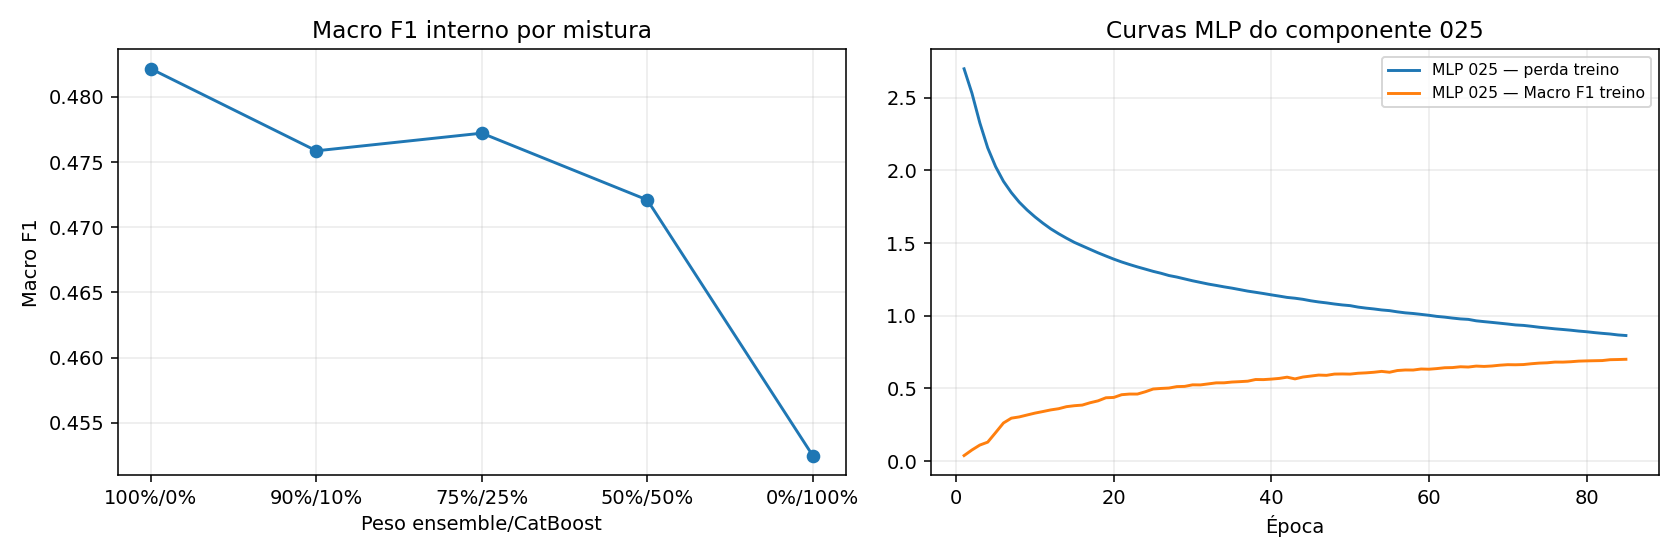

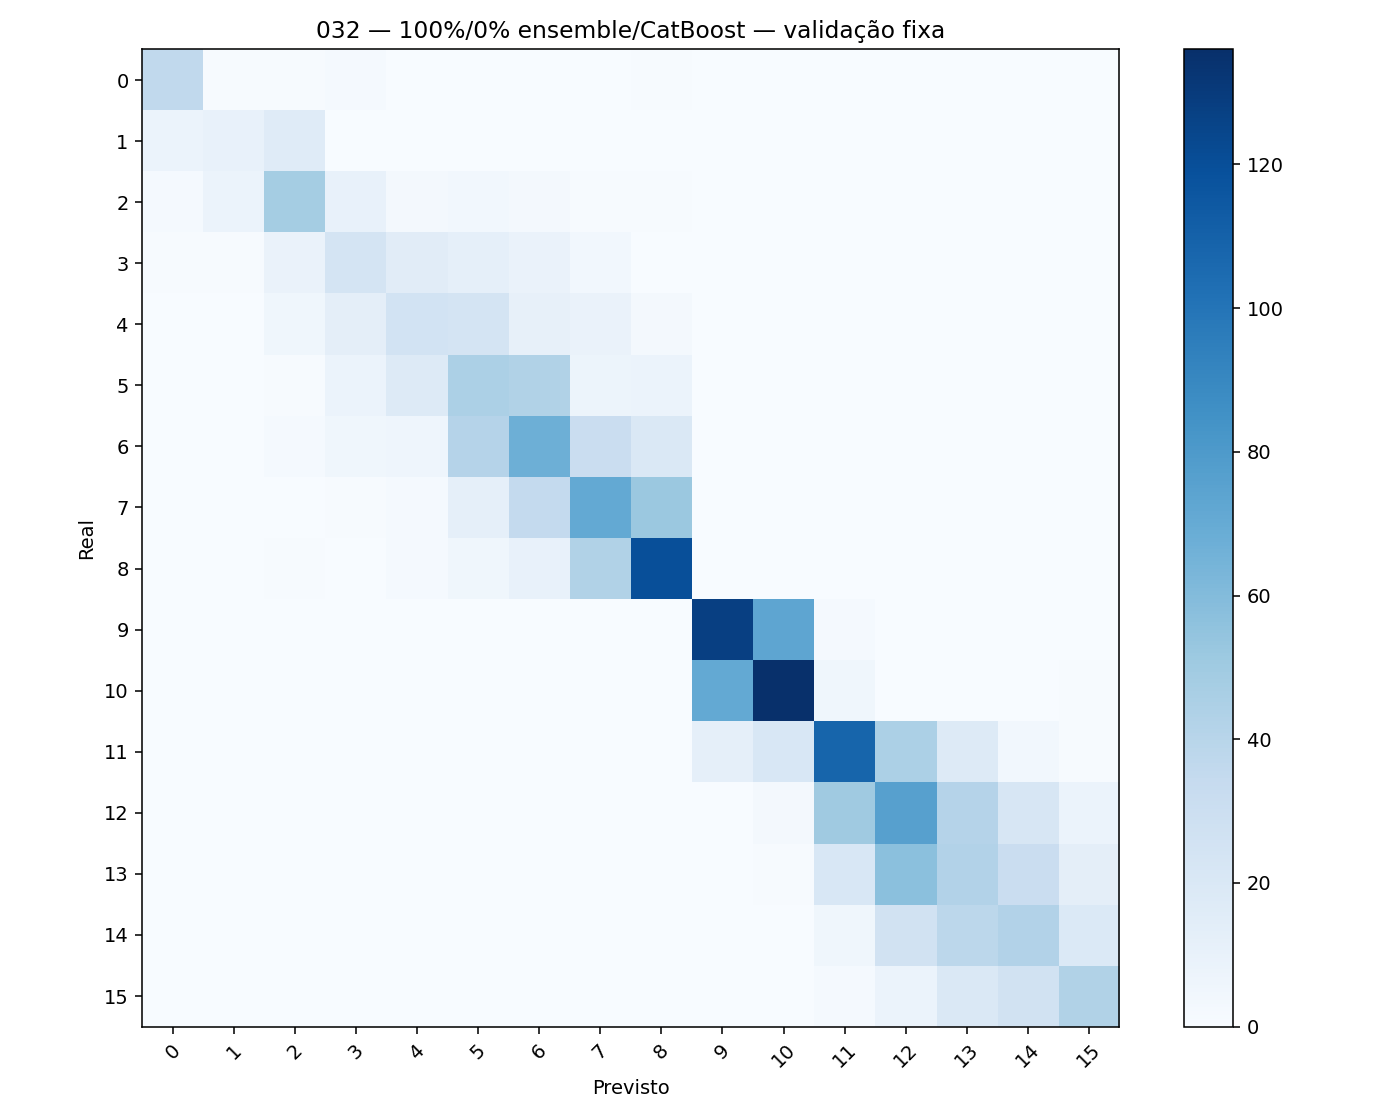

CSV: {'path': None, 'duplicate_of': ['submission_025_xgboost_mlp_dropout.csv'], 'differences': {'submission_016_xgboost_mlp015.csv': 202, 'submission_019_ensemble_pesos.csv': 424, 'submission_025_xgboost_mlp_dropout.csv': 0, 'submission_028_ensemble_features_dominio.csv': 500, 'submission_029_catboost.csv': 1210}, 'reason': 'As previsões reproduzem uma submissão anterior.'}
/Users/eduardaferreira/daa-kaggle-2026-2027/reports/experiments_030_032.md


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import pandas as pd

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_030_032.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_030_032 import run_032, write_final_report

result = run_032()
display(pd.DataFrame([{**row, 'macro_f1_interna': row['internal_metrics']['macro_f1']} for row in result['internal_candidates']]).drop(columns=['internal_metrics']))
print('Selecionada internamente:', result['selected_internally'])
print('Componentes na validação fixa:', result['component_validation_metrics'])
print('Mistura escolhida:', result['fixed_metrics_selected_blend'])
display(Image(filename=str(root / result['curves'])))
display(Image(filename=str(root / result['confusion_matrix'])))
print('CSV:', result['submission'])
print(write_final_report())

## Conclusão e decisão

- Data: 14/11
- Conclusão: 100/0 (ensemble 025 sem CatBoost) venceu internamente (F1 0,4822). Na validação fixa manteve 0,4615; as previsões reproduzem exatamente a submissão 025. Não foi criado CSV novo.
- Melhorias: testar outro componente apenas com seleção interna e validação independente futura.